In [53]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, recall_score, balanced_accuracy_score, precision_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer

In [54]:
dt_labeled = pd.read_csv("../../data/clean/decisiontree/dt_labeled.csv")
print(f"The dimensions of dt_labeled are: {dt_labeled.shape}")
print(f"The number of unique participants in this dataset are: {dt_labeled["participant_id"].nunique()}")
dt_labeled.head().T

The dimensions of dt_labeled are: (8729, 26)
The number of unique participants in this dataset are: 47


,0,1,2,3,4
participant_id,P2,P2,P2,P2,P2
calendarDate,2026-05-09,2026-05-10,2026-05-11,2026-05-12,2026-05-16
cohort,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03
durationInMs,24120000.0,22620000.0,26040000.0,23940000.0,17940000.0
deepSleepDurationInMs,7020000.0,5280000.0,5700000.0,5640000.0,2160000.0
lightSleepDurationInMs,11700000.0,9660000.0,15240000.0,13140000.0,10980000.0
remSleepInMs,5400000.0,7680000.0,5100000.0,5160000.0,4800000.0
awakeDurationInMs,60000.0,0.0,60000.0,120000.0,120000.0
overallSleepScore,79.0,76.0,73.0,81.0,62.0
breathsPerMinute_mean,16.035746,16.368302,16.775543,16.971122,17.72412


In [55]:
y = dt_labeled["low_oxygen"]
groups = dt_labeled["participant_id"]

features_to_remove = [
    "participant_id",
    "cohort",
    "calendarDate",
    "low_oxygen"
]

X = dt_labeled.drop(columns = features_to_remove)

print(y.shape,X.shape)

(8729,) (8729, 22)


In [56]:
# Train/test split pattern adapted from the scikit-learn StratifiedGroupKFold documentation example
# modified to use a single split and this project's columns.

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(sgkf.split(X,y,groups = groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train size: {len(train_idx)}")
print(f"Test size: {len(test_idx)}")

Train size: 7029
Test size: 1700


## Feature Checks

In [60]:
from matplotlib.colors import LinearSegmentedColormap

#ai tools used to help verify plotting code was accurate throughout the notebook, not write the code from scratch

print("X_train shape:", X_train.shape)
X_train.head().T

X_train shape: (7029, 22)


,0,1,2,3,4
durationInMs,2.412000e+07,2.262000e+07,2.604000e+07,2.394000e+07,1.794000e+07
deepSleepDurationInMs,7.020000e+06,5.280000e+06,5.700000e+06,5.640000e+06,2.160000e+06
lightSleepDurationInMs,1.170000e+07,9.660000e+06,1.524000e+07,1.314000e+07,1.098000e+07
remSleepInMs,5.400000e+06,7.680000e+06,5.100000e+06,5.160000e+06,4.800000e+06
awakeDurationInMs,6.000000e+04,0.000000e+00,6.000000e+04,1.200000e+05,1.200000e+05
overallSleepScore,7.900000e+01,7.600000e+01,7.300000e+01,8.100000e+01,6.200000e+01
breathsPerMinute_mean,1.603575e+01,1.636830e+01,1.677554e+01,1.697112e+01,1.772412e+01
breathsPerMinute_std,2.567794e+00,2.305960e+00,2.519712e+00,2.117889e+00,2.379074e+00
breathsPerMinute_min,8.000000e+00,7.080000e+00,9.000000e+00,9.250000e+00,8.830000e+00
breathsPerMinute_max,2.258000e+01,2.250000e+01,2.225000e+01,2.175000e+01,2.400000e+01


feature importance. When two columns carry the same information, like resting and minimum heart rate at 0.87, the tree may split the credit between them or give it all to one, more or less by chance. So if minimum heart rate ranks high and resting heart rate ranks low, that doesn’t mean resting heart rate doesn’t matter. keep all 22 features.

## Verifying Test/Train Split Numbers

In [61]:
print(f"People in both sets: {len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))}")
print(f"People in total: {len(set(groups.iloc[train_idx]) | set(groups.iloc[test_idx]))}")
print(f"{len(groups.iloc[train_idx])} + {len(groups.iloc[test_idx])} = {len(groups.iloc[train_idx]) + len(groups.iloc[test_idx])}")

People in both sets: 0
People in total: 47
7029 + 1700 = 8729


In [62]:
print(f"Training set low-oxygen count: {y_train.sum()}")
print(f"Testing set low-oxygen count: {y_test.sum()}")
print(f"Training: {groups.iloc[train_idx].nunique()} people, {len(train_idx)} nights, {(y_train.mean()*100).round(2)}% low oxygen")
print(f"Testing: {groups.iloc[test_idx].nunique()} people, {len(test_idx)} nights, {(y_test.mean()*100).round(2)}% low oxygen")
print("With training and test split such that there are 35 + 12 = 47 (100%) people and 7029 + 1700 = 8729 (100%) nights, " \
"\n we can conclude that no person appears in both sets")

print(len(test_idx)-y_test.sum())

Training set low-oxygen count: 1101
Testing set low-oxygen count: 213
Training: 35 people, 7029 nights, 15.66% low oxygen
Testing: 12 people, 1700 nights, 12.53% low oxygen
With training and test split such that there are 35 + 12 = 47 (100%) people and 7029 + 1700 = 8729 (100%) nights, 
 we can conclude that no person appears in both sets
1487


Imagine every person is a bag of marbles, where red marbles are low-oxygen nights. The split has to move whole bags, because a person can’t be cut in half. Most bags have a few red marbles. But P22’s bag has 245 red marbles, and P19’s has 231. Together, those two bags hold more than a third of all 1,314 red marbles. Wherever those two heavy bags land, they drag the percentages with them, and with only 47 bags total, there aren’t enough small bags to even it out.

## Decision Tree Classifiers

### Decision Tree 1 (Grid Search CV)

In [63]:
# below code was adapted from https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
# Hyperparameter tuning performed using sklearn's GridSearchCV.
# Candidate parameter values were selected based on sklearn DecisionTreeClassifier documentation.

cv = StratifiedGroupKFold(n_splits=5,shuffle=True, random_state=42)

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 7, 8, 10, None],
    'min_samples_split': [50, 100, 150, 200, 30],
    'min_samples_leaf': [1, 20, 30, 50, 100, 150, 200, 300],
    'criterion': ['gini', 'entropy']
}

grid = GridSearchCV(estimator=DecisionTreeClassifier(random_state=42, class_weight="balanced"), param_grid=param_grid, cv=cv, scoring='balanced_accuracy', n_jobs=-1)

grid.fit(X_train, y_train, groups=groups.iloc[train_idx])



,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 20, ...], 'min_samples_split': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchang

In [64]:
df = pd.DataFrame(grid.cv_results_)

df = df[["mean_test_score","std_test_score","rank_test_score","param_criterion","param_max_depth","param_min_samples_leaf","param_min_samples_split"]].sort_values("mean_test_score", ascending=False)
df.head(10)

,mean_test_score,std_test_score,rank_test_score,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split
691,0.650956,0.135139,1,entropy,None,30,100
449,0.649702,0.137813,2,entropy,4,20,30
445,0.649702,0.137813,2,entropy,4,20,50
446,0.649611,0.137771,4,entropy,4,20,100
440,0.649457,0.137850,5,entropy,4,1,50
444,0.649457,0.137850,5,entropy,4,1,30
441,0.649366,0.137808,7,entropy,4,1,100
447,0.649128,0.138287,8,entropy,4,20,150
448,0.649128,0.138287,8,entropy,4,20,200
442,0.648883,0.138323,10,entropy,4,1,150


In [65]:
print(grid.best_params_)
print(grid.best_score_)



{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 30, 'min_samples_split': 100}
0.6509564802766382


In [66]:
tree1 = DecisionTreeClassifier(criterion="entropy", max_depth = 4, min_samples_leaf=20, min_samples_split= 30, class_weight="balanced", random_state=42)

tree1.fit(X = X_train, y = y_train)

predictions1 = tree1.predict(X=X_test)

print(sum(predictions1))

522


#### Confusion Matrices and Results

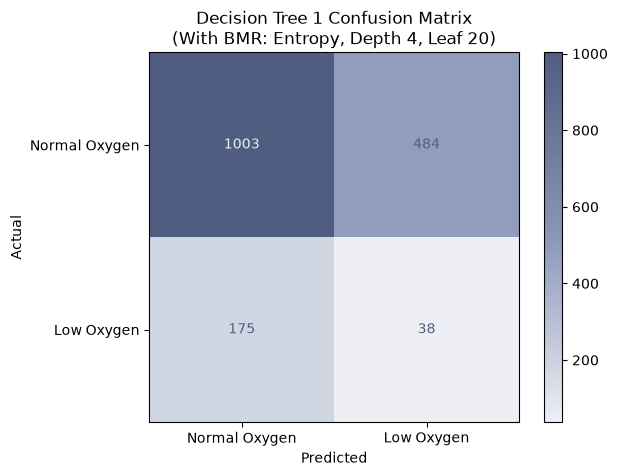

In [67]:
# code adapted from inclass notebook
# Generating the confusion matrix


dt_cmap = LinearSegmentedColormap.from_list("site_diverging", ["#EDEFF5", "#8A97B8", "#4F5D80"]) #establish suite of theme colors
cm1 = confusion_matrix(y_test, predictions1)

disp = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=["Normal Oxygen","Low Oxygen"])
disp.plot(cmap = dt_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Decision Tree 1 Confusion Matrix\n(With BMR: Entropy, Depth 4, Leaf 20)');
plt.savefig("../../images/dectrees/decision_tree_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [68]:
# Accuracy, F1 Score and Recall Score

accuracy1 = np.round(accuracy_score(y_test, predictions1),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


f11 = np.round(f1_score(y_test, predictions1),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

recall1 = np.round(recall_score(y_test, predictions1),3)
bas1 = np.round(balanced_accuracy_score(y_test, predictions1),3)
ps1 = np.round(precision_score(y_test, predictions1),3)
baseline1 = np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {accuracy1}')
print(f'F1 Score: {f11}')
print(f'Recall Score: {recall1}')
print(f'Balanced Accuracy Score: {bas1}')
print(f'Precision Score: {ps1}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {baseline1}')

Accuracy: 0.612
F1 Score: 0.103
Recall Score: 0.178
Balanced Accuracy Score: 0.426
Precision Score: 0.073
Baseline Accuracy if model predicts "no" for every observation: 0.875


### Decision Tree 2 (Gini, max_depth = 3)

In [69]:
tree2 = DecisionTreeClassifier(criterion="gini", max_depth = 3, class_weight= "balanced", random_state=42)

tree2.fit(X = X_train, y = y_train)

predictions2 = tree2.predict(X=X_test)

print(sum(predictions2))

258


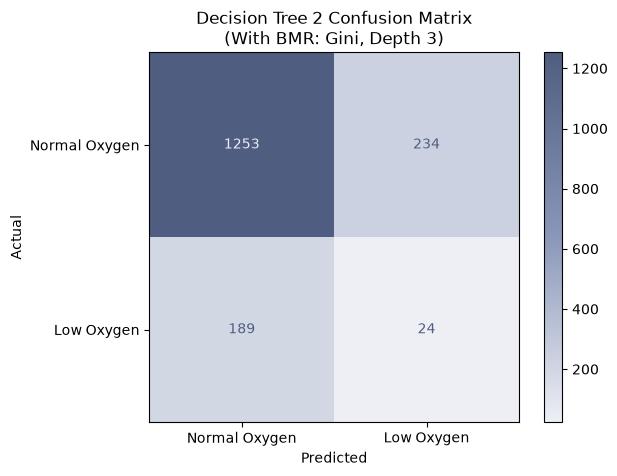

In [70]:
# code adapted from inclass notebook
# Generating the confusion matrix



cm2 = confusion_matrix(y_test, predictions2)

disp = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=["Normal Oxygen","Low Oxygen"])
disp.plot(cmap = dt_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Decision Tree 2 Confusion Matrix\n(With BMR: Gini, Depth 3)');
plt.savefig("../../images/dectrees/decision_tree_2_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [71]:
# Accuracy, F1 Score and Recall Score

accuracy2 = np.round(accuracy_score(y_test, predictions2),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


f12 = np.round(f1_score(y_test, predictions2),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

recall2 = np.round(recall_score(y_test, predictions2),3)
bas2 = np.round(balanced_accuracy_score(y_test, predictions2),3)
ps2 = np.round(precision_score(y_test, predictions2),3)
baseline2= np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {accuracy2}')
print(f'F1 Score: {f12}')
print(f'Recall Score: {recall2}')
print(f'Balanced Accuracy Score: {bas2}')
print(f'Precision Score: {ps2}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {baseline2}')

Accuracy: 0.751
F1 Score: 0.102
Recall Score: 0.113
Balanced Accuracy Score: 0.478
Precision Score: 0.093
Baseline Accuracy if model predicts "no" for every observation: 0.875


### Decision Tree 3 (Entropy, max_depth = 3)

In [72]:
tree3 = DecisionTreeClassifier(criterion="entropy", max_depth = 3, class_weight= "balanced", random_state=42)

tree3.fit(X = X_train, y = y_train)

predictions3 = tree3.predict(X=X_test)

print(sum(predictions3))

258


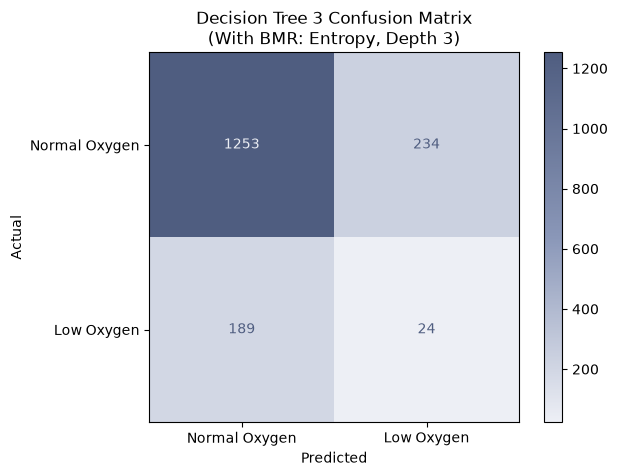

In [73]:
# code adapted from inclass notebook
# Generating the confusion matrix

cm3 = confusion_matrix(y_test, predictions3)

disp = ConfusionMatrixDisplay(confusion_matrix=cm3, display_labels=["Normal Oxygen","Low Oxygen"])
disp.plot(cmap = dt_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Decision Tree 3 Confusion Matrix\n(With BMR: Entropy, Depth 3)');
plt.savefig("../../images/dectrees/decision_tree_3_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [74]:
# Accuracy, F1 Score and Recall Score

accuracy3 = np.round(accuracy_score(y_test, predictions3),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


f13 = np.round(f1_score(y_test, predictions3),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

recall3 = np.round(recall_score(y_test, predictions3),3)
bas3 = np.round(balanced_accuracy_score(y_test, predictions3),3)
ps3 = np.round(precision_score(y_test, predictions3),3)
baseline3 = np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {accuracy3}')
print(f'F1 Score: {f13}')
print(f'Recall Score: {recall3}')
print(f'Balanced Accuracy Score: {bas3}')
print(f'Precision Score: {ps3}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {baseline3}')

Accuracy: 0.751
F1 Score: 0.102
Recall Score: 0.113
Balanced Accuracy Score: 0.478
Precision Score: 0.093
Baseline Accuracy if model predicts "no" for every observation: 0.875


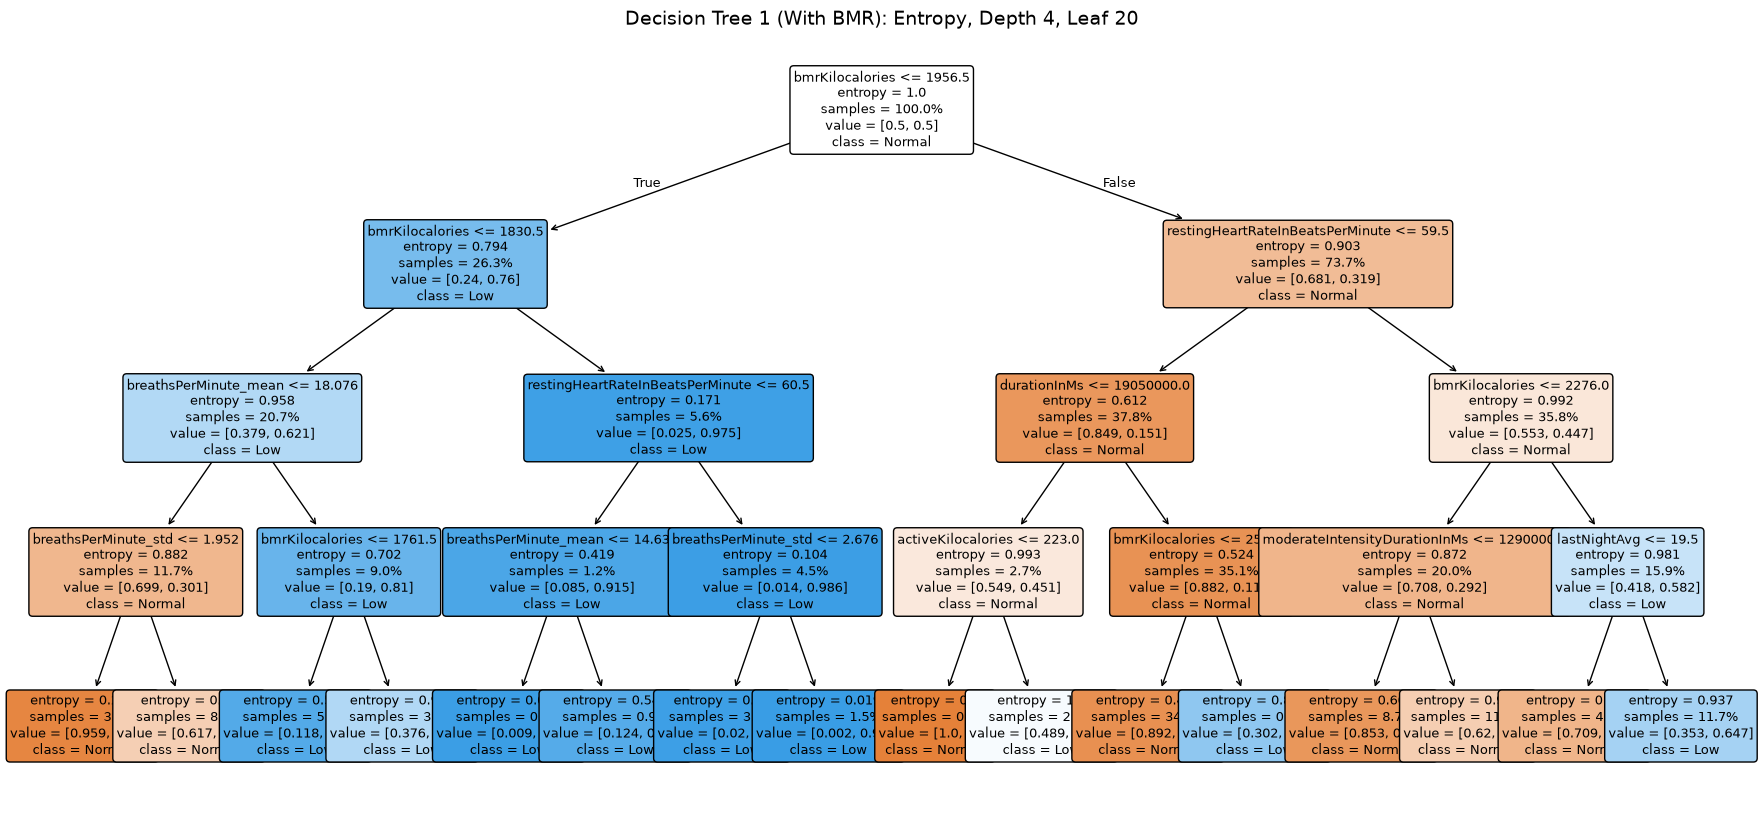

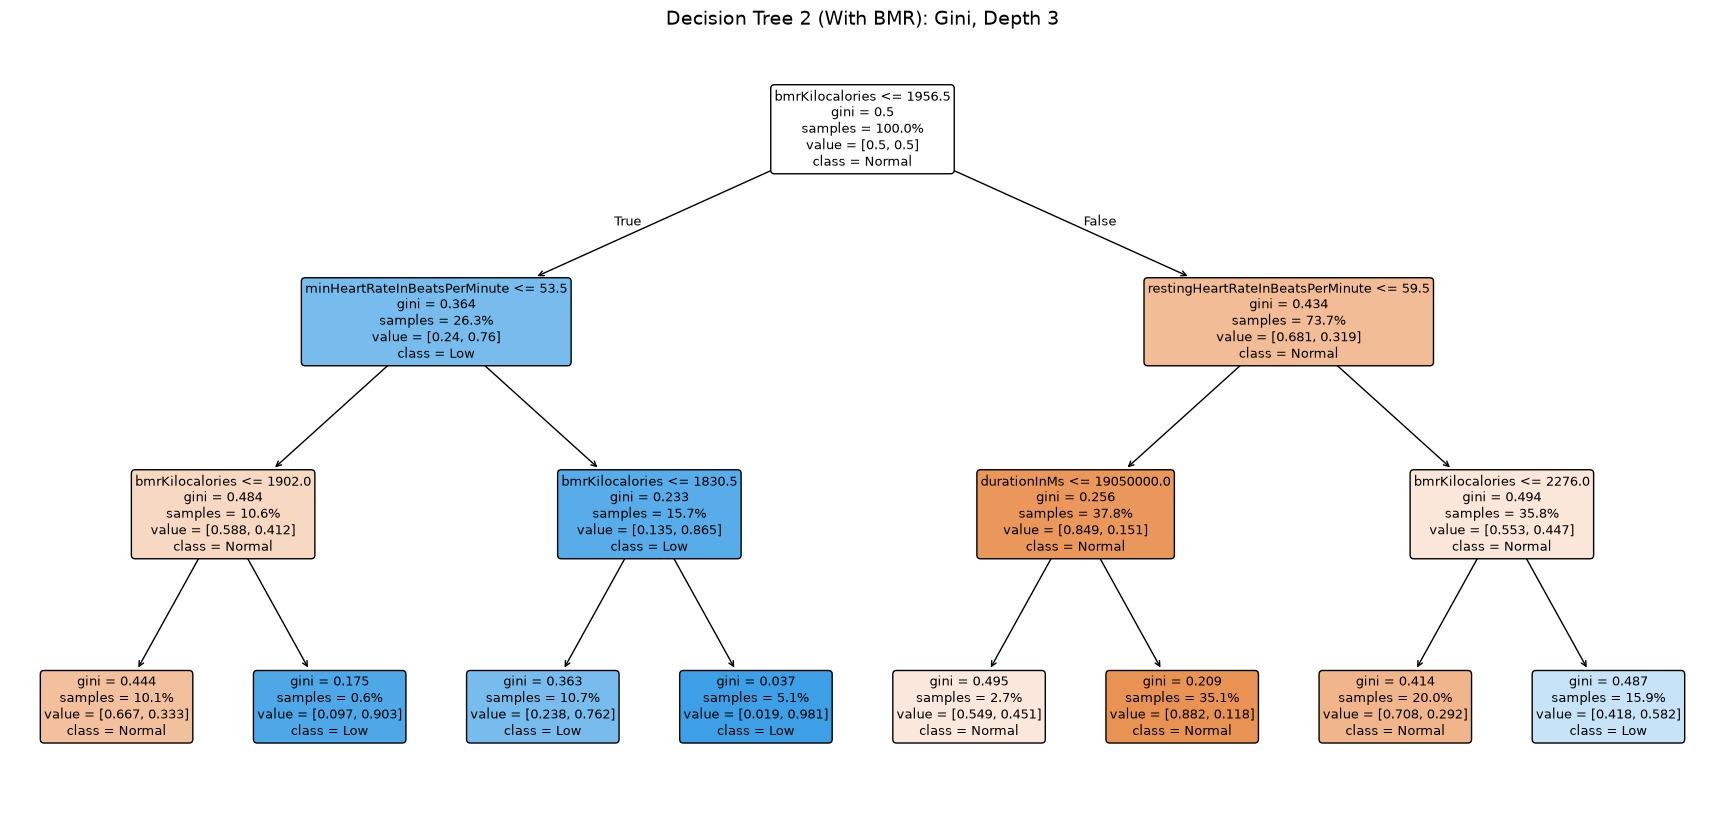

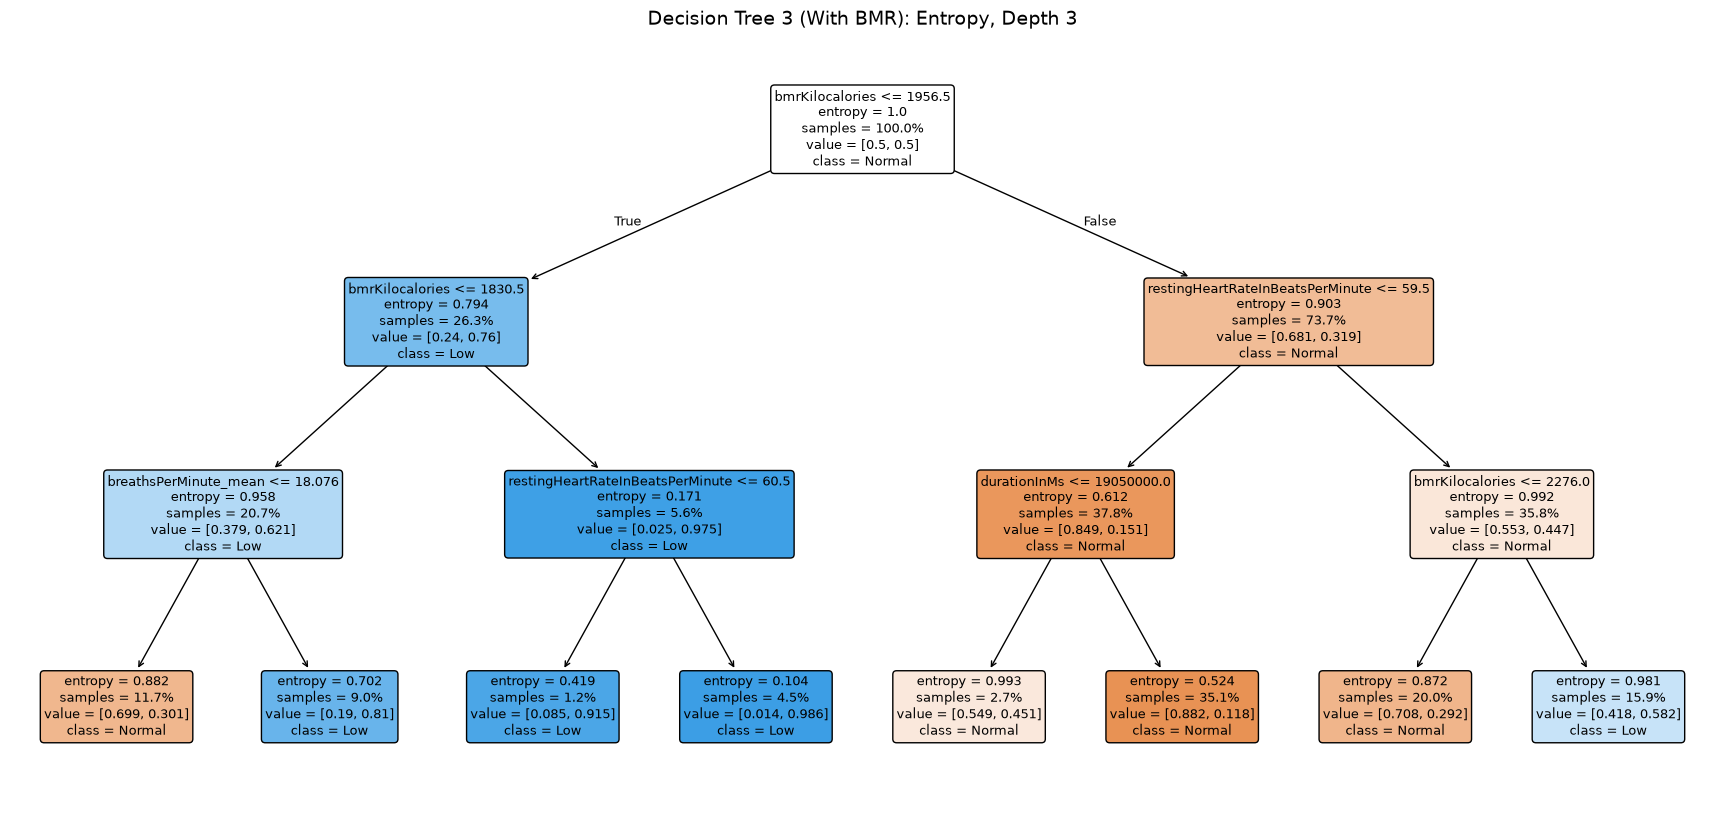

In [75]:
from sklearn.tree import plot_tree

for tree, name, title in [(tree1, "tree1", "Decision Tree 1 (With BMR): Entropy, Depth 4, Leaf 20"),
                          (tree2, "tree2", "Decision Tree 2 (With BMR): Gini, Depth 3"),
                          (tree3, "tree3", "Decision Tree 3 (With BMR): Entropy, Depth 3")]:
    fig, ax = plt.subplots(figsize=(22, 10))
    plot_tree(tree, feature_names=list(X_train.columns), class_names=["Normal", "Low"],
              filled=True, rounded=True, fontsize=9, impurity=True, proportion=True, ax=ax)
    ax.set_title(title, fontsize=14)
    fig.savefig(f"../../images/dectrees/{name}_plot.png", dpi=150, bbox_inches="tight")

#### Dropping bmrKilocalories because the trees are splitting primarily on that value which is not an indicator of the night but rather the person

In [76]:
dropped_X_train, dropped_X_test = X_train.drop(columns="bmrKilocalories"), X_test.drop(columns = "bmrKilocalories")

## Training Data Snippet for Website

In [92]:
pd.concat([dropped_X_train,y.iloc[train_idx]], axis = 1).head(8).round(2).T

,0,1,2,3,4,5,6,7
durationInMs,24120000.0,22620000.0,26040000.0,23940000.0,17940000.0,23880000.0,30600000.0,22260000.0
deepSleepDurationInMs,7020000.0,5280000.0,5700000.0,5640000.0,2160000.0,8820000.0,4260000.0,8460000.0
lightSleepDurationInMs,11700000.0,9660000.0,15240000.0,13140000.0,10980000.0,9120000.0,19620000.0,11580000.0
remSleepInMs,5400000.0,7680000.0,5100000.0,5160000.0,4800000.0,5940000.0,6720000.0,2220000.0
awakeDurationInMs,60000.0,0.0,60000.0,120000.0,120000.0,0.0,60000.0,180000.0
overallSleepScore,79.0,76.0,73.0,81.0,62.0,82.0,84.0,71.0
breathsPerMinute_mean,16.04,16.37,16.78,16.97,17.72,16.27,16.71,16.75
breathsPerMinute_std,2.57,2.31,2.52,2.12,2.38,2.32,2.36,2.55
breathsPerMinute_min,8.0,7.08,9.0,9.25,8.83,8.16,8.75,8.58
breathsPerMinute_max,22.58,22.5,22.25,21.75,24.0,22.33,22.66,22.66


## Testing Data Snippet for Website

In [93]:
pd.concat([dropped_X_train,y.iloc[train_idx]], axis = 1).head(8).round(2).T

,0,1,2,3,4,5,6,7
durationInMs,24120000.0,22620000.0,26040000.0,23940000.0,17940000.0,23880000.0,30600000.0,22260000.0
deepSleepDurationInMs,7020000.0,5280000.0,5700000.0,5640000.0,2160000.0,8820000.0,4260000.0,8460000.0
lightSleepDurationInMs,11700000.0,9660000.0,15240000.0,13140000.0,10980000.0,9120000.0,19620000.0,11580000.0
remSleepInMs,5400000.0,7680000.0,5100000.0,5160000.0,4800000.0,5940000.0,6720000.0,2220000.0
awakeDurationInMs,60000.0,0.0,60000.0,120000.0,120000.0,0.0,60000.0,180000.0
overallSleepScore,79.0,76.0,73.0,81.0,62.0,82.0,84.0,71.0
breathsPerMinute_mean,16.04,16.37,16.78,16.97,17.72,16.27,16.71,16.75
breathsPerMinute_std,2.57,2.31,2.52,2.12,2.38,2.32,2.36,2.55
breathsPerMinute_min,8.0,7.08,9.0,9.25,8.83,8.16,8.75,8.58
breathsPerMinute_max,22.58,22.5,22.25,21.75,24.0,22.33,22.66,22.66


In [94]:
pd.concat([dropped_X_train,y.iloc[train_idx]], axis = 1).to_csv("../../data/clean/decisiontree/dt_train.csv", index = False)
pd.concat([dropped_X_test,y.iloc[test_idx]], axis = 1).to_csv("../../data/clean/decisiontree/dt_test.csv", index = False)

In [95]:
# below code was adapted from https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
# Hyperparameter tuning performed using sklearn's GridSearchCV.
# Candidate parameter values were selected based on sklearn DecisionTreeClassifier documentation.

cv = StratifiedGroupKFold(n_splits=5,shuffle=True, random_state=42)

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 7, 8, 10, None],
    'min_samples_split': [50, 100, 150, 200, 30],
    'min_samples_leaf': [1, 20, 30, 50, 100, 150, 200, 300, 400, 500, 600, 700, 1000],
    'criterion': ['gini', 'entropy']
}

grid = GridSearchCV(estimator=DecisionTreeClassifier(random_state=42, class_weight="balanced"), param_grid=param_grid, cv=cv, scoring='balanced_accuracy', n_jobs=-1)

grid.fit(dropped_X_train, y_train, groups=groups.iloc[train_idx])

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 20, ...], 'min_samples_split': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchang

In [96]:
dropped_df = pd.DataFrame(grid.cv_results_)

dropped_df = dropped_df[["mean_test_score","std_test_score","rank_test_score","param_criterion","param_max_depth","param_min_samples_leaf","param_min_samples_split"]].sort_values("mean_test_score", ascending=False)
dropped_df.head(10)

,mean_test_score,std_test_score,rank_test_score,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split
828,0.641073,0.084037,1,entropy,5,500,200
1020,0.641073,0.084037,1,entropy,8,500,50
955,0.641073,0.084037,1,entropy,7,500,50
827,0.641073,0.084037,1,entropy,5,500,150
829,0.641073,0.084037,1,entropy,5,500,30
1024,0.641073,0.084037,1,entropy,8,500,30
1023,0.641073,0.084037,1,entropy,8,500,200
1022,0.641073,0.084037,1,entropy,8,500,150
1021,0.641073,0.084037,1,entropy,8,500,100
890,0.641073,0.084037,1,entropy,6,500,50


In [97]:
dropped_tree1 = DecisionTreeClassifier(criterion="entropy", max_depth = 5, min_samples_leaf=500, min_samples_split= 200, class_weight="balanced", random_state=42)

dropped_tree1.fit(X = dropped_X_train, y = y_train)

dropped_predictions1 = dropped_tree1.predict(X=dropped_X_test)

print(sum(dropped_predictions1))

788


##### Confusion Matrices and Results

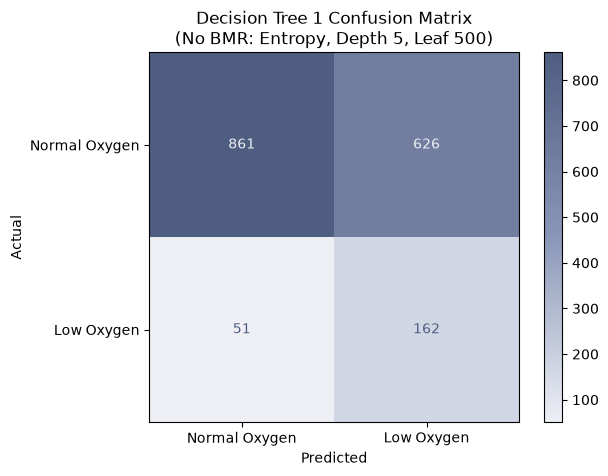

In [98]:
# code adapted from inclass notebook
# Generating the confusion matrix


dropped_cm1 = confusion_matrix(y_test, dropped_predictions1)

disp = ConfusionMatrixDisplay(confusion_matrix=dropped_cm1, display_labels=["Normal Oxygen","Low Oxygen"])
disp.plot(cmap = dt_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Decision Tree 1 Confusion Matrix\n(No BMR: Entropy, Depth 5, Leaf 500)');
plt.savefig("../../images/dectrees/dropped_decision_tree_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [99]:
# Accuracy, F1 Score and Recall Score

dropped_accuracy1 = np.round(accuracy_score(y_test, dropped_predictions1),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


dropped_f11 = np.round(f1_score(y_test, dropped_predictions1),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

dropped_recall1= np.round(recall_score(y_test, dropped_predictions1),3)
dropped_bas1 = np.round(balanced_accuracy_score(y_test,dropped_predictions1),3)
dropped_ps1 = np.round(precision_score(y_test, dropped_predictions1),3)
dropped_baseline1 = np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {dropped_accuracy1}')
print(f'F1 Score: {dropped_f11}')
print(f'Recall Score: {dropped_recall1}')
print(f'Balanced Accuracy Score: {dropped_bas1}')
print(f'Precision Score: {dropped_ps1}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {dropped_baseline1}')

Accuracy: 0.602
F1 Score: 0.324
Recall Score: 0.761
Balanced Accuracy Score: 0.67
Precision Score: 0.206
Baseline Accuracy if model predicts "no" for every observation: 0.875


#### Tree 2


In [100]:
dropped_tree2 = DecisionTreeClassifier(criterion="gini", max_depth = 3, class_weight="balanced", random_state=42)

dropped_tree2.fit(X = dropped_X_train, y = y_train)

dropped_predictions2 = dropped_tree2.predict(X=dropped_X_test)

print(sum(dropped_predictions2))

638


##### Confusion Matrices and Results


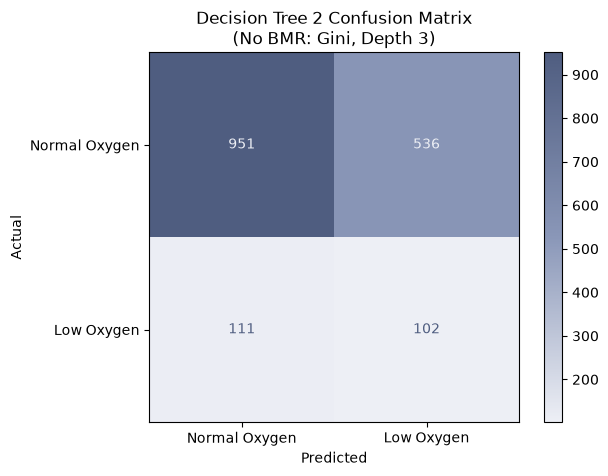

In [101]:
# code adapted from inclass notebook
# Generating the confusion matrix


dropped_cm2 = confusion_matrix(y_test, dropped_predictions2)

disp = ConfusionMatrixDisplay(confusion_matrix=dropped_cm2, display_labels=["Normal Oxygen","Low Oxygen"])
disp.plot(cmap = dt_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Decision Tree 2 Confusion Matrix\n(No BMR: Gini, Depth 3)');
plt.savefig("../../images/dectrees/dropped_decision_tree2_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [102]:
# Accuracy, F1 Score and Recall Score

dropped_accuracy2 = np.round(accuracy_score(y_test, dropped_predictions2),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


dropped_f12 = np.round(f1_score(y_test, dropped_predictions2),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

dropped_recall2= np.round(recall_score(y_test, dropped_predictions2),3)
dropped_bas2 = np.round(balanced_accuracy_score(y_test,dropped_predictions2),3)
dropped_ps2 = np.round(precision_score(y_test, dropped_predictions2),3)
dropped_baseline2 = np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {dropped_accuracy2}')
print(f'F1 Score: {dropped_f12}')
print(f'Recall Score: {dropped_recall2}')
print(f'Balanced Accuracy Score: {dropped_bas2}')
print(f'Precision Score: {dropped_ps2}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {dropped_baseline2}')

Accuracy: 0.619
F1 Score: 0.24
Recall Score: 0.479
Balanced Accuracy Score: 0.559
Precision Score: 0.16
Baseline Accuracy if model predicts "no" for every observation: 0.875


#### Tree 3


In [103]:
dropped_tree3 = DecisionTreeClassifier(criterion="entropy", max_depth = 3, class_weight="balanced", random_state=42)

dropped_tree3.fit(X = dropped_X_train, y = y_train)

dropped_predictions3 = dropped_tree3.predict(X=dropped_X_test)

print(sum(dropped_predictions3))

523


##### Confusion Matrices and Results


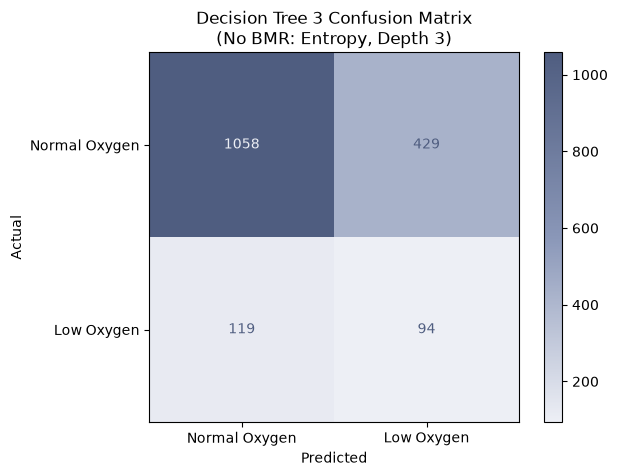

In [104]:
# code adapted from inclass notebook
# Generating the confusion matrix


dropped_cm3 = confusion_matrix(y_test, dropped_predictions3)

disp = ConfusionMatrixDisplay(confusion_matrix=dropped_cm3, display_labels=["Normal Oxygen","Low Oxygen"])
disp.plot(cmap = dt_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Decision Tree 3 Confusion Matrix\n(No BMR: Entropy, Depth 3)');
plt.savefig("../../images/dectrees/dropped_decision_tree3_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [105]:
# Accuracy, F1 Score and Recall Score

dropped_accuracy3 = np.round(accuracy_score(y_test, dropped_predictions3),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


dropped_f13 = np.round(f1_score(y_test, dropped_predictions3),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

dropped_recall3= np.round(recall_score(y_test, dropped_predictions3),3)
dropped_bas3 = np.round(balanced_accuracy_score(y_test,dropped_predictions3),3)
dropped_ps3 = np.round(precision_score(y_test, dropped_predictions3),3)
dropped_baseline3 = np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {dropped_accuracy3}')
print(f'F1 Score: {dropped_f13}')
print(f'Recall Score: {dropped_recall3}')
print(f'Balanced Accuracy Score: {dropped_bas3}')
print(f'Precision Score: {dropped_ps3}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {dropped_baseline3}')

Accuracy: 0.678
F1 Score: 0.255
Recall Score: 0.441
Balanced Accuracy Score: 0.576
Precision Score: 0.18
Baseline Accuracy if model predicts "no" for every observation: 0.875


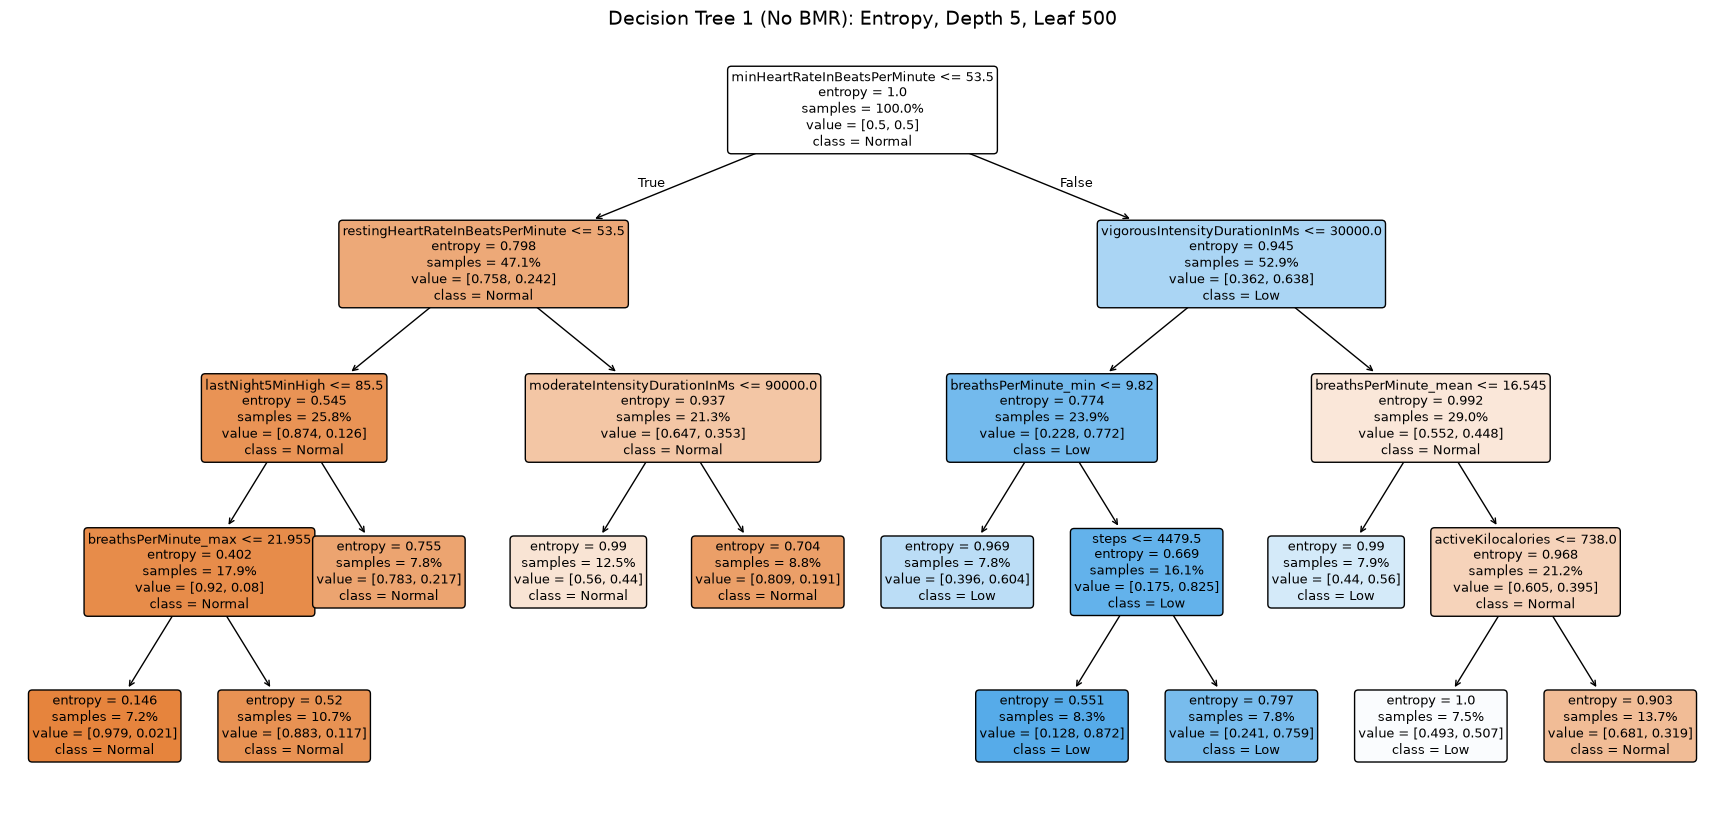

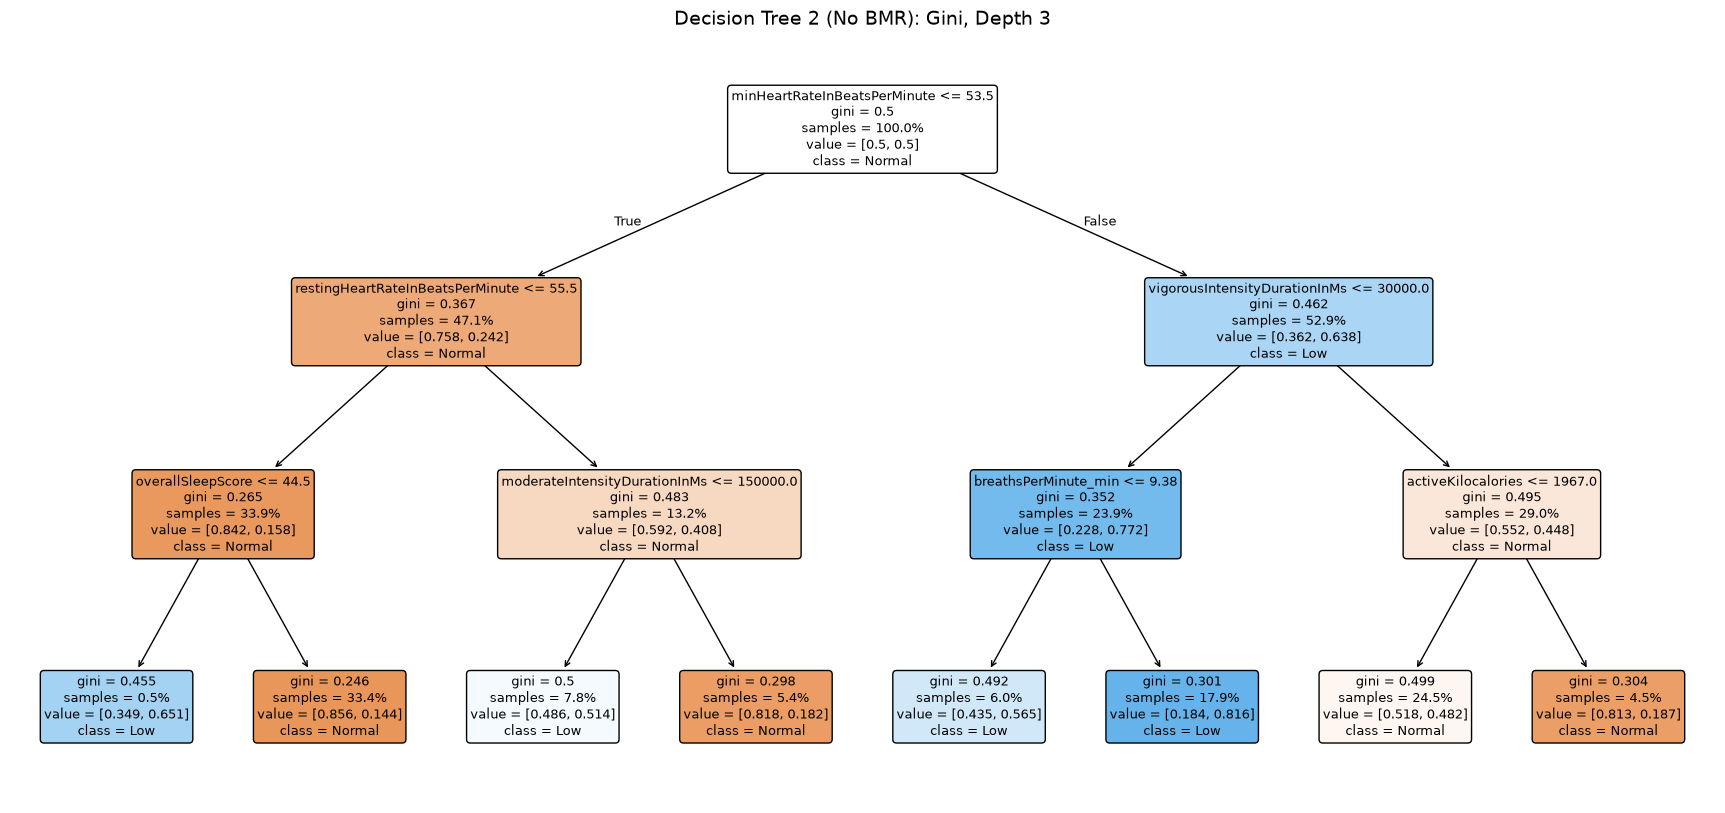

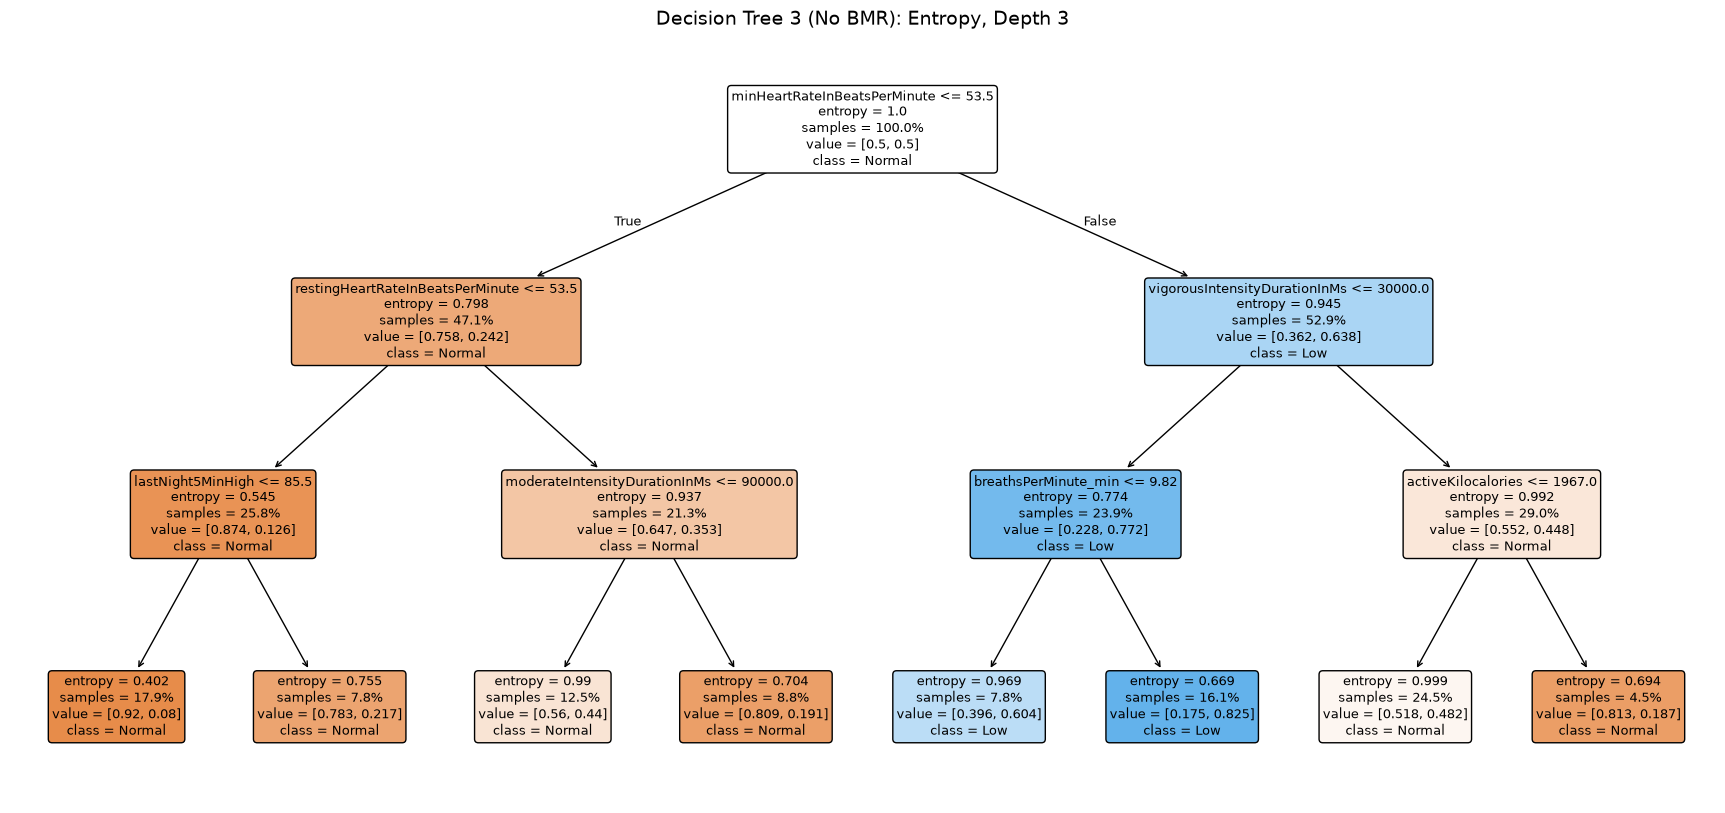

In [106]:
for tree, name, title in [(dropped_tree1, "dropped_tree1", "Decision Tree 1 (No BMR): Entropy, Depth 5, Leaf 500"),
                          (dropped_tree2, "dropped_tree2", "Decision Tree 2 (No BMR): Gini, Depth 3"),
                          (dropped_tree3, "dropped_tree3", "Decision Tree 3 (No BMR): Entropy, Depth 3")]:
    fig, ax = plt.subplots(figsize=(22, 10))
    plot_tree(tree, feature_names=list(dropped_X_train.columns), class_names=["Normal", "Low"],
              filled=True, rounded=True, fontsize=9, impurity=True, proportion=True, ax=ax)
    ax.set_title(title, fontsize=14)
    fig.savefig(f"../../images/dectrees/{name}_plot.png", dpi=150, bbox_inches="tight")

#### Feature Importance


In [107]:
dropped_importance1 = pd.Series(dropped_tree1.feature_importances_, index = dropped_X_train.columns).sort_values(ascending=False)

dropped_importance1

minHeartRateInBeatsPerMinute        0.484735
vigorousIntensityDurationInMs       0.238754
restingHeartRateInBeatsPerMinute    0.083745
breathsPerMinute_min                0.058316
moderateIntensityDurationInMs       0.037999
activeKilocalories                  0.021683
breathsPerMinute_mean               0.021190
steps                               0.020421
lastNight5MinHigh                   0.020006
breathsPerMinute_max                0.013153
maxStressInStressLevel              0.000000
averageStressInStressLevel          0.000000
maxHeartRateInBeatsPerMinute        0.000000
durationInMs                        0.000000
deepSleepDurationInMs               0.000000
breathsPerMinute_std                0.000000
overallSleepScore                   0.000000
awakeDurationInMs                   0.000000
remSleepInMs                        0.000000
lightSleepDurationInMs              0.000000
lastNightAvg                        0.000000
dtype: float64